In [1]:
import sklearn, cv2, tensorflow
print("Kernel OK")

Kernel OK


In [2]:
import os, cv2, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

DATA_DIR = "../data"
IMG_SIZE = 64
N_PER_CLASS = 200

class_names = sorted([d for d in os.listdir(DATA_DIR)
                      if os.path.isdir(os.path.join(DATA_DIR, d))])
print("Classes:", class_names)

X, y = [], []
for label, cls in enumerate(class_names):
    folder = os.path.join(DATA_DIR, cls)
    for f in os.listdir(folder)[:N_PER_CLASS]:
        img = cv2.imread(os.path.join(folder, f))
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X.append(img)
        y.append(label)

X = np.array(X)
y = np.array(y)
print("Images:", X.shape, "Labels:", y.shape)

Classes: ['Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_healthy']
Images: (600, 64, 64, 3) Labels: (600,)


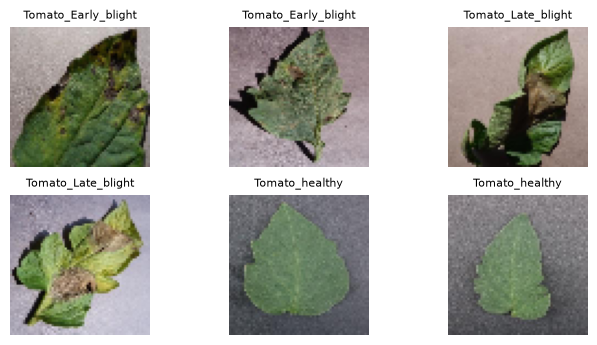

In [3]:
plt.figure(figsize=(8, 4))
for i in range(6):
    idx = i * 100
    plt.subplot(2, 3, i + 1)
    plt.imshow(X[idx])
    plt.title(class_names[y[idx]], fontsize=8)
    plt.axis("off")
plt.show()


In [4]:
# 0-255 pixel values ah 0-1 ku maathrom
X_norm = X.astype("float32") / 255.0

# Photo ah oru nera line ah maathrom (SVM, RF ku venum)
X_flat = X_norm.reshape(len(X_norm), -1)

# 80% padikka, 20% exam ku
X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

# Next notebooks la use panna save pannrom
np.savez("../processed.npz", X=X_norm, X_flat=X_flat, y=y,
         X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,
         class_names=class_names)
print("Saved!")


Train: (480, 12288) Test: (120, 12288)
Saved!


In [5]:

import numpy as np

data = np.load("../processed.npz", allow_pickle=True)

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]
class_names = data["class_names"].tolist()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Classes:", class_names)



Training data: (480, 12288)
Testing data: (120, 12288)
Classes: ['Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_healthy']


In [6]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = SVC(kernel="linear", C=1.0, random_state=42)

svm_model.fit(X_train, y_train)

svm_predictions = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_predictions)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    svm_predictions,
    target_names=class_names,
    zero_division=0
))


SVM Accuracy: 78.33 %

Classification Report:

                     precision    recall  f1-score   support

Tomato_Early_blight       0.75      0.82      0.79        40
 Tomato_Late_blight       0.79      0.68      0.73        40
     Tomato_healthy       0.81      0.85      0.83        40

           accuracy                           0.78       120
          macro avg       0.78      0.78      0.78       120
       weighted avg       0.78      0.78      0.78       120



In [7]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=class_names,
    zero_division=0
))


Random Forest Accuracy: 79.17 %

Classification Report:

                     precision    recall  f1-score   support

Tomato_Early_blight       0.80      0.80      0.80        40
 Tomato_Late_blight       0.73      0.68      0.70        40
     Tomato_healthy       0.84      0.90      0.87        40

           accuracy                           0.79       120
          macro avg       0.79      0.79      0.79       120
       weighted avg       0.79      0.79      0.79       120



In [8]:

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["SVM", "Random Forest"],
    "Accuracy (%)": [
        round(svm_accuracy * 100, 2),
        round(rf_accuracy * 100, 2)
    ]
})

print(comparison.to_string(index=False))


        Model  Accuracy (%)
          SVM         78.33
Random Forest         79.17


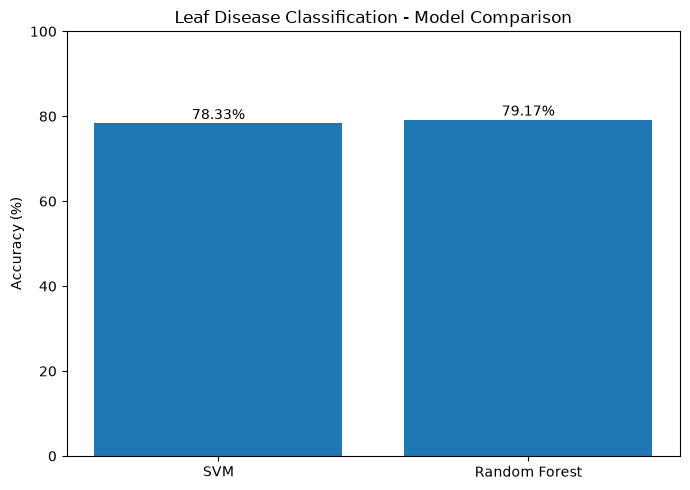

In [9]:

import matplotlib.pyplot as plt

models = ["SVM", "Random Forest"]
accuracies = [
    svm_accuracy * 100,
    rf_accuracy * 100
]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies)

plt.title("Leaf Disease Classification - Model Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [10]:

import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(svm_model, "../models/svm_model.pkl")
joblib.dump(rf_model, "../models/random_forest_model.pkl")

print("Both models saved successfully!")


Both models saved successfully!


In [12]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=15,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    dt_predictions,
    target_names=class_names,
    zero_division=0
))

Decision Tree Accuracy: 52.5 %

Classification Report:

                     precision    recall  f1-score   support

Tomato_Early_blight       0.46      0.47      0.47        40
 Tomato_Late_blight       0.53      0.47      0.50        40
     Tomato_healthy       0.58      0.62      0.60        40

           accuracy                           0.53       120
          macro avg       0.52      0.53      0.52       120
       weighted avg       0.52      0.53      0.52       120



In [13]:

comparison = pd.DataFrame({
    "Model": ["SVM", "Random Forest", "Decision Tree"],
    "Accuracy (%)": [
        round(svm_accuracy * 100, 2),
        round(rf_accuracy * 100, 2),
        round(dt_accuracy * 100, 2)
    ]
})

print(comparison.to_string(index=False))


        Model  Accuracy (%)
          SVM         78.33
Random Forest         79.17
Decision Tree         52.50


In [14]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm_linear = SVC(kernel="linear", C=1.0)
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_poly = SVC(kernel="poly", C=1.0, degree=3, gamma="scale")

svm_kernel_results = []

for name, model in [
    ("Linear SVM", svm_linear),
    ("RBF SVM", svm_rbf),
    ("Polynomial SVM", svm_poly)
]:
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    svm_kernel_results.append({
        "Kernel": name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

svm_kernel_df = pd.DataFrame(svm_kernel_results)
print(svm_kernel_df.to_string(index=False))


        Kernel  Accuracy (%)
    Linear SVM         78.33
       RBF SVM         85.00
Polynomial SVM         79.17


In [15]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

tree_counts = [50, 100, 200]
rf_results = []
rf_candidates = {}

for n in tree_counts:
    model = RandomForestClassifier(
        n_estimators=n,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    rf_candidates[n] = model
    rf_results.append({
        "Number of Trees": n,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

rf_df = pd.DataFrame(rf_results)
print(rf_df.to_string(index=False))

best_n = max(
    rf_results,
    key=lambda result: result["Accuracy (%)"]
)["Number of Trees"]

best_rf_model = rf_candidates[best_n]

print("\nBest tree count:", best_n)
print("Best accuracy:", round(
    max(r["Accuracy (%)"] for r in rf_results), 2
), "%")


 Number of Trees  Accuracy (%)
              50         75.00
             100         79.17
             200         80.83

Best tree count: 200
Best accuracy: 80.83 %


In [16]:

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95, svd_solver="full")

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train.shape[1])
print("PCA components:", pca.n_components_)
print("Reduced training shape:", X_train_pca.shape)
print("Reduced testing shape:", X_test_pca.shape)
print("Explained variance:", round(
    np.sum(pca.explained_variance_ratio_) * 100, 2
), "%")


Original number of features: 12288
PCA components: 248
Reduced training shape: (480, 248)
Reduced testing shape: (120, 248)
Explained variance: 95.0 %


Number of clusters: 3
Cluster sizes: [294 174  12]
Adjusted Rand Index: 0.1624


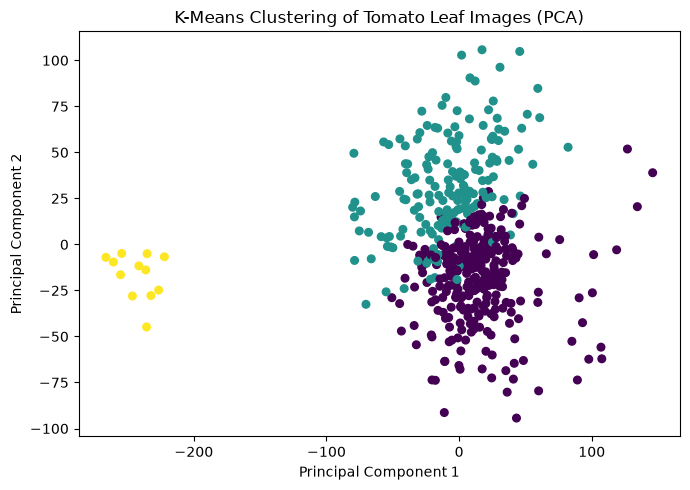

In [17]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_train_pca)

ari = adjusted_rand_score(y_train, cluster_labels)

print("Number of clusters:", kmeans.n_clusters)
print("Cluster sizes:", __import__("numpy").bincount(cluster_labels))
print("Adjusted Rand Index:", round(ari, 4))

plt.figure(figsize=(7, 5))
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=30
)
plt.title("K-Means Clustering of Tomato Leaf Images (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()


In [18]:

import torch
import torch.nn as nn
import torch.optim as optim

print("PyTorch version:", torch.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")


ModuleNotFoundError: No module named 'torch'

In [19]:

%pip install torch


  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.1/124.1 MB 1.6 MB/s eta 0:01:18
   ---------------------------------------- 0.2/124.1 MB 2.1 MB/s eta 0:01:00
   ---------------------------------------- 0.4/124.1 MB 3.4 MB/s eta 0:00:36
   ---------------------------------------- 0.8/124.1 MB 4.4 MB/s eta 0:00:28
   ---------------------------------------- 1.1/124.1 MB 4.7 MB/s eta 0:00:27
   ---------------------------------------- 1.2/124.1 MB 4.4 MB/s eta 0:00:29
    --------------------------------------- 1.6/124.1 MB 5.1 MB/s eta 0:00:25
    --------------------------------------- 2.0/124.1 MB 5.2 MB/s eta 0:00:24
    --------------------------------------- 2.3


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:

import torch
import torch.nn as nn
import torch.optim as optim

print("PyTorch version:", torch.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")


PyTorch version: 2.14.1+cpu
Device: CPU


In [21]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

torch.manual_seed(42)

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

class LeafFNN(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

fnn_model = LeafFNN(
    input_size=X_train.shape[1],
    num_classes=len(class_names)
)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(fnn_model.parameters(), lr=0.001)

EPOCHS = 15

for epoch in range(EPOCHS):
    fnn_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = fnn_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{EPOCHS}], "
        f"Loss: {total_loss / len(train_loader):.4f}"
    )

fnn_model.eval()

with torch.no_grad():
    outputs = fnn_model(X_test_tensor)
    fnn_predictions = torch.argmax(outputs, dim=1).numpy()

fnn_accuracy = accuracy_score(y_test, fnn_predictions)

print("\nFNN Accuracy:", round(fnn_accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    fnn_predictions,
    target_names=class_names,
    zero_division=0
))


Epoch [1/15], Loss: 1.5397
Epoch [2/15], Loss: 1.1372
Epoch [3/15], Loss: 1.0786
Epoch [4/15], Loss: 1.0090
Epoch [5/15], Loss: 0.9523
Epoch [6/15], Loss: 0.9105
Epoch [7/15], Loss: 0.8418
Epoch [8/15], Loss: 0.8151
Epoch [9/15], Loss: 0.7616
Epoch [10/15], Loss: 0.7923
Epoch [11/15], Loss: 0.7972
Epoch [12/15], Loss: 0.7292
Epoch [13/15], Loss: 0.7359
Epoch [14/15], Loss: 0.7273
Epoch [15/15], Loss: 0.6761

FNN Accuracy: 75.0 %

Classification Report:

                     precision    recall  f1-score   support

Tomato_Early_blight       0.73      0.93      0.81        40
 Tomato_Late_blight       0.67      0.70      0.68        40
     Tomato_healthy       0.93      0.62      0.75        40

           accuracy                           0.75       120
          macro avg       0.77      0.75      0.75       120
       weighted avg       0.77      0.75      0.75       120



In [22]:

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Load original images
data = np.load("../processed.npz", allow_pickle=True)
X_images = data["X"]
y = data["y"].astype(np.int64)
class_names = data["class_names"].tolist()

# Recreate the same stratified train-test split
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_img_train = X_images[train_idx]
X_img_test = X_images[test_idx]
y_img_train = y[train_idx]
y_img_test = y[test_idx]

# Convert images from NHWC to NCHW for PyTorch
X_train_cnn = torch.tensor(
    X_img_train.transpose(0, 3, 1, 2),
    dtype=torch.float32
)
X_test_cnn = torch.tensor(
    X_img_test.transpose(0, 3, 1, 2),
    dtype=torch.float32
)
y_train_cnn = torch.tensor(y_img_train, dtype=torch.long)

train_loader_cnn = DataLoader(
    TensorDataset(X_train_cnn, y_train_cnn),
    batch_size=32,
    shuffle=True
)

# Define CNN architecture
class LeafCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

torch.manual_seed(42)

cnn_model = LeafCNN(num_classes=len(class_names))
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

EPOCHS = 10

for epoch in range(EPOCHS):
    cnn_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader_cnn:
        optimizer.zero_grad()
        outputs = cnn_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{EPOCHS}], "
        f"Loss: {total_loss / len(train_loader_cnn):.4f}"
    )

# Evaluate CNN
cnn_model.eval()
with torch.no_grad():
    outputs = cnn_model(X_test_cnn)
    cnn_predictions = torch.argmax(outputs, dim=1).numpy()

cnn_accuracy = accuracy_score(y_img_test, cnn_predictions)

print("\nCNN Accuracy:", round(cnn_accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(
    y_img_test,
    cnn_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))


Epoch [1/10], Loss: 1.0996
Epoch [2/10], Loss: 1.0687
Epoch [3/10], Loss: 0.9191
Epoch [4/10], Loss: 0.6792
Epoch [5/10], Loss: 0.5385
Epoch [6/10], Loss: 0.4717
Epoch [7/10], Loss: 0.4395
Epoch [8/10], Loss: 0.4348
Epoch [9/10], Loss: 0.3979
Epoch [10/10], Loss: 0.3538

CNN Accuracy: 88.33 %

Classification Report:

                     precision    recall  f1-score   support

Tomato_Early_blight       0.82      0.90      0.86        40
 Tomato_Late_blight       0.84      0.80      0.82        40
     Tomato_healthy       1.00      0.95      0.97        40

           accuracy                           0.88       120
          macro avg       0.89      0.88      0.88       120
       weighted avg       0.89      0.88      0.88       120



Epoch [1/5], D Loss: 1.1725, G Loss: 1.1407
Epoch [2/5], D Loss: 1.0439, G Loss: 1.5236
Epoch [3/5], D Loss: 0.7713, G Loss: 1.8118
Epoch [4/5], D Loss: 0.7051, G Loss: 1.9128
Epoch [5/5], D Loss: 0.7062, G Loss: 2.1804


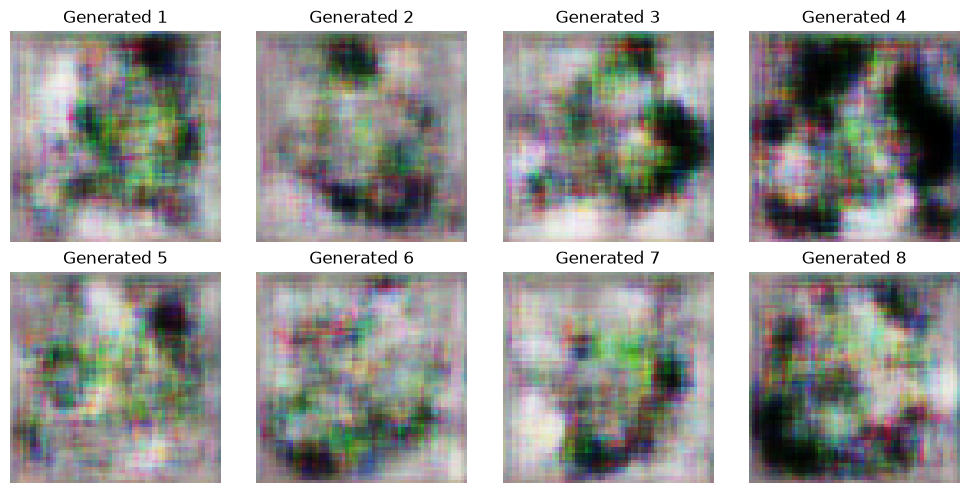

In [23]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

# Load normalized images
data = np.load("../processed.npz", allow_pickle=True)
X_images = data["X"].astype(np.float32)

# Convert RGB images from [0, 1] to [-1, 1]
X_gan = X_images.transpose(0, 3, 1, 2)
X_gan = (X_gan * 2.0) - 1.0

gan_dataset = TensorDataset(torch.tensor(X_gan))
gan_loader = DataLoader(
    gan_dataset,
    batch_size=32,
    shuffle=True
)

# Generator: noise -> 64x64 RGB image
class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(latent_dim, 256 * 8 * 8),
            nn.ReLU(True),
            nn.Unflatten(1, (256, 8, 8)),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(64, 3, 3, padding=1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.network(z)

# Discriminator: image -> real/fake score
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

latent_dim = 100
generator = Generator(latent_dim)
discriminator = Discriminator()

criterion_gan = nn.BCELoss()
optimizer_g = torch.optim.Adam(
    generator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
optimizer_d = torch.optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

EPOCHS_GAN = 5

for epoch in range(EPOCHS_GAN):
    generator.train()
    discriminator.train()
    total_d_loss = 0
    total_g_loss = 0

    for (real_images,) in gan_loader:
        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, 1)
        fake_labels = torch.zeros(batch_size, 1)

        # Train discriminator
        optimizer_d.zero_grad()

        real_output = discriminator(real_images)
        real_loss = criterion_gan(real_output, real_labels)

        noise = torch.randn(batch_size, latent_dim)
        fake_images = generator(noise)
        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion_gan(fake_output, fake_labels)

        d_loss = real_loss + fake_loss
        d_loss.backward()
        optimizer_d.step()

        # Train generator
        optimizer_g.zero_grad()

        noise = torch.randn(batch_size, latent_dim)
        generated_images = generator(noise)
        generated_output = discriminator(generated_images)

        g_loss = criterion_gan(generated_output, real_labels)
        g_loss.backward()
        optimizer_g.step()

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    print(
        f"Epoch [{epoch+1}/{EPOCHS_GAN}], "
        f"D Loss: {total_d_loss / len(gan_loader):.4f}, "
        f"G Loss: {total_g_loss / len(gan_loader):.4f}"
    )

# Generate and display 8 synthetic images
generator.eval()
with torch.no_grad():
    noise = torch.randn(8, latent_dim)
    generated_images = generator(noise).cpu()
    generated_images = (generated_images + 1) / 2

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image = generated_images[i].permute(1, 2, 0).numpy()
    ax.imshow(np.clip(image, 0, 1))
    ax.axis("off")
    ax.set_title(f"Generated {i+1}")

plt.tight_layout()
plt.show()


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 79.17 %

Test Accuracy: 86.67 %

Classification Report:

                     precision    recall  f1-score   support

Tomato_Early_blight       0.79      0.93      0.85        40
 Tomato_Late_blight       0.90      0.70      0.79        40
     Tomato_healthy       0.93      0.97      0.95        40

           accuracy                           0.87       120
          macro avg       0.87      0.87      0.86       120
       weighted avg       0.87      0.87      0.86       120



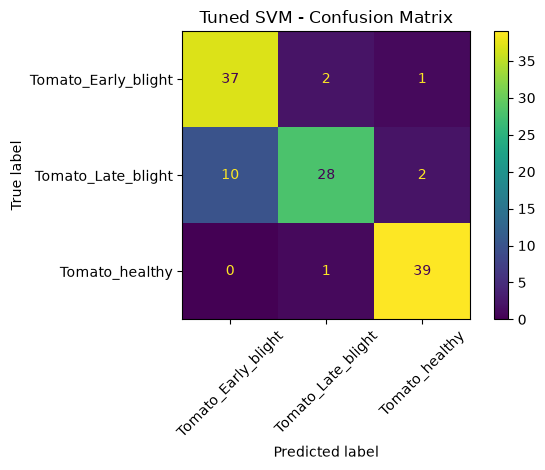

In [24]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Hyperparameter combinations to test
param_grid = {
    "kernel": ["rbf"],
    "C": [0.1, 1, 10],
    "gamma": ["scale", "auto"]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

# Train using training data only
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:",
      round(grid_search.best_score_ * 100, 2), "%")

# Evaluate the selected model on the held-out test set
best_svm_model = grid_search.best_estimator_
tuned_predictions = best_svm_model.predict(X_test)

tuned_accuracy = accuracy_score(y_test, tuned_predictions)

print("\nTest Accuracy:", round(tuned_accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    tuned_predictions,
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, tuned_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(xticks_rotation=45)
plt.title("Tuned SVM - Confusion Matrix")
plt.tight_layout()
plt.show()


In [25]:

import os
import joblib
import json

# Project root is the parent of the notebooks folder
PROJECT_ROOT = os.path.abspath("..")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")

os.makedirs(MODELS_DIR, exist_ok=True)

# Save the tuned SVM model
joblib.dump(
    best_svm_model,
    os.path.join(MODELS_DIR, "best_svm_model.pkl")
)

# Save class labels
with open(
    os.path.join(MODELS_DIR, "class_names.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(class_names, f, indent=4)

print("Model and class names saved successfully!")
print("Models directory:", MODELS_DIR)
print("Saved files:", os.listdir(MODELS_DIR))


Model and class names saved successfully!
Models directory: c:\Users\Udhayan\OneDrive\Desktop\leaf-disease-detection\models
Saved files: ['best_svm_model.pkl', 'class_names.json', 'random_forest_model.pkl', 'svm_model.pkl']
